In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

customers = pd.DataFrame({
    "Customer_ID": range(1001, 1001 + n),
    "Age": np.random.randint(18, 70, n),
    "Tenure_Months": np.random.randint(1, 61, n),
    "Monthly_Spend_NGN": np.random.randint(2000, 100000, n),
    "Complaints": np.random.randint(0, 6, n),
    "Late_Payments": np.random.randint(0, 5, n)
})

# Simulated churn outcome
churn_score = (
    customers["Complaints"] * 0.35
    + customers["Late_Payments"] * 0.30
    - customers["Tenure_Months"] * 0.015
    + np.random.normal(0, 0.8, n)
)

customers["Churn"] = (churn_score > 1.5).astype(int)

print("Dataset shape:", customers.shape)
print("\nChurn distribution:")
print(customers["Churn"].value_counts())
display(customers.head())

Dataset shape: (1000, 7)

Churn distribution:
Churn
0    672
1    328
Name: count, dtype: int64


,Customer_ID,Age,Tenure_Months,Monthly_Spend_NGN,Complaints,Late_Payments,Churn
0,1001,56,35,20787,4,2,0
1,1002,69,51,50845,2,3,0
2,1003,46,15,59932,1,4,1
3,1004,32,25,94124,5,2,0
4,1005,60,55,93659,0,0,0


In [2]:
# Overall customer churn rate
churn_rate = customers["Churn"].mean() * 100

print(f"Total customers: {len(customers)}")
print(f"Customers who churned: {customers['Churn'].sum()}")
print(f"Customer churn rate: {churn_rate:.2f}%")

# Compare churned and retained customers
churn_summary = customers.groupby("Churn").agg(
    Customer_Count=("Customer_ID", "count"),
    Average_Tenure=("Tenure_Months", "mean"),
    Average_Monthly_Spend=("Monthly_Spend_NGN", "mean"),
    Average_Complaints=("Complaints", "mean"),
    Average_Late_Payments=("Late_Payments", "mean")
).round(2)

churn_summary.index = ["Retained", "Churned"]
display(churn_summary)

Total customers: 1000
Customers who churned: 328
Customer churn rate: 32.80%


,Customer_Count,Average_Tenure,Average_Monthly_Spend,Average_Complaints,Average_Late_Payments
Retained,672,33.76,51125.69,2.11,1.60
Churned,328,25.57,51347.14,3.50,2.65


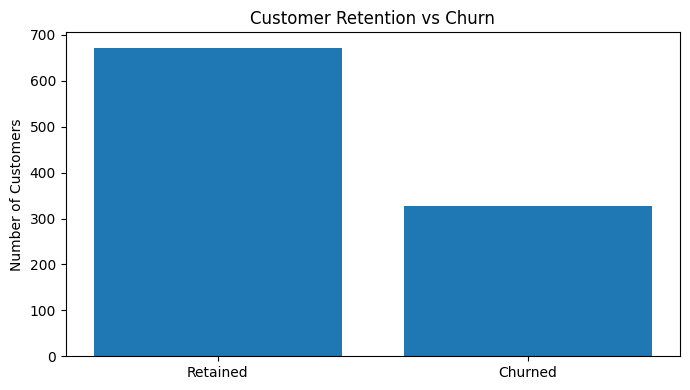

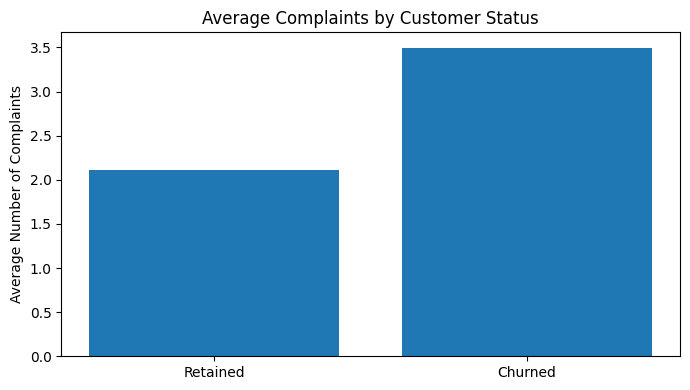

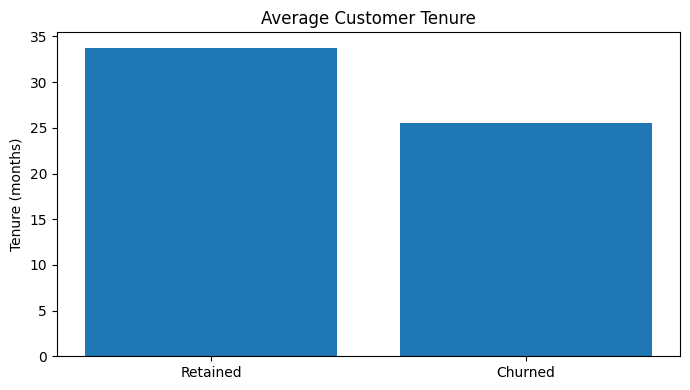

In [3]:
import matplotlib.pyplot as plt

# Chart 1: Retained vs churned customers
churn_counts = customers["Churn"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Retained", "Churned"],
    [churn_counts.get(0, 0), churn_counts.get(1, 0)]
)
plt.title("Customer Retention vs Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Chart 2: Average complaints by churn status
complaints = customers.groupby("Churn")["Complaints"].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Retained", "Churned"],
    [complaints.get(0, 0), complaints.get(1, 0)]
)
plt.title("Average Complaints by Customer Status")
plt.ylabel("Average Number of Complaints")
plt.tight_layout()
plt.show()

# Chart 3: Average tenure by churn status
tenure = customers.groupby("Churn")["Tenure_Months"].mean()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Retained", "Churned"],
    [tenure.get(0, 0), tenure.get(1, 0)]
)
plt.title("Average Customer Tenure")
plt.ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Prepare features and target
X = customers.drop(columns=["Customer_ID", "Churn"])
y = customers["Churn"]

# Split data while preserving the churn proportion
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, class_weight="balanced"
    )
}

# Train and evaluate
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(precision_score(
            y_test, predictions, zero_division=0
        ), 3),
        "Recall": round(recall_score(
            y_test, predictions, zero_division=0
        ), 3),
        "F1 Score": round(f1_score(
            y_test, predictions, zero_division=0
        ), 3),
        "ROC-AUC": round(roc_auc_score(y_test, probabilities), 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.775,0.691,0.576,0.628,0.834
1,Random Forest,0.750,0.643,0.545,0.590,0.765


FEATURE IMPORTANCE


,Feature,Importance
3,Complaints,0.223046
1,Tenure_Months,0.213418
2,Monthly_Spend_NGN,0.207947
0,Age,0.181313
4,Late_Payments,0.174276


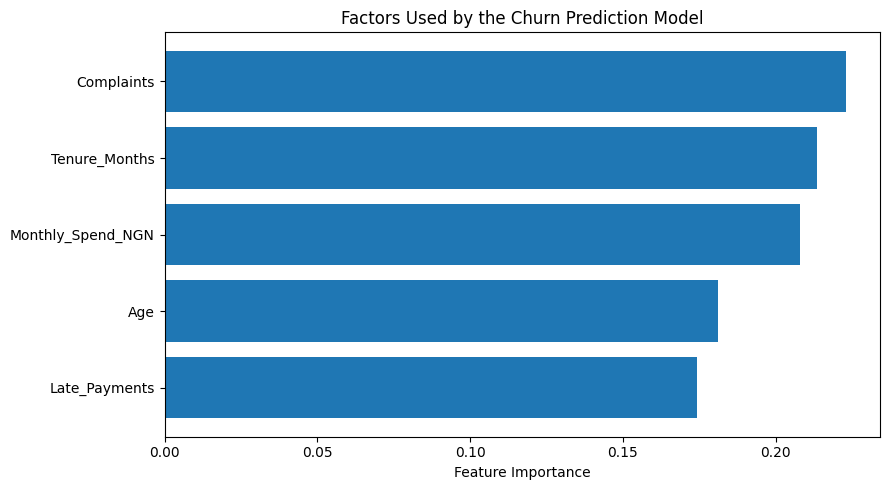

In [5]:
# Extract feature importance from the trained Random Forest
rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("FEATURE IMPORTANCE")
display(importance)

# Visualize feature importance
plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"][::-1],
    importance["Importance"][::-1]
)
plt.title("Factors Used by the Churn Prediction Model")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [6]:
# Summarize model performance
print("CUSTOMER CHURN PREDICTION REPORT")
print("=" * 40)

display(results_df)

# Summarize observed customer behaviour
summary = customers.groupby("Churn").agg(
    Customers=("Customer_ID", "count"),
    Avg_Tenure=("Tenure_Months", "mean"),
    Avg_Complaints=("Complaints", "mean"),
    Avg_Late_Payments=("Late_Payments", "mean"),
    Avg_Monthly_Spend=("Monthly_Spend_NGN", "mean")
).round(2)

summary.index = ["Retained", "Churned"]
print("\nCUSTOMER PROFILE COMPARISON")
display(summary)

print("\nBUSINESS RECOMMENDATIONS")
print("1. Monitor customer complaints and resolve recurring issues.")
print("2. Review payment difficulties and offer appropriate support.")
print("3. Develop retention strategies for newer customers.")
print("4. Track churn and retention rates over time.")
print("5. Validate these patterns with real customer data before acting.")

CUSTOMER CHURN PREDICTION REPORT


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.775,0.691,0.576,0.628,0.834
1,Random Forest,0.750,0.643,0.545,0.590,0.765



CUSTOMER PROFILE COMPARISON


,Customers,Avg_Tenure,Avg_Complaints,Avg_Late_Payments,Avg_Monthly_Spend
Retained,672,33.76,2.11,1.60,51125.69
Churned,328,25.57,3.50,2.65,51347.14



BUSINESS RECOMMENDATIONS
1. Monitor customer complaints and resolve recurring issues.
2. Review payment difficulties and offer appropriate support.
3. Develop retention strategies for newer customers.
4. Track churn and retention rates over time.
5. Validate these patterns with real customer data before acting.


# Customer Churn Analysis and Prediction

## Objective
Explore customer churn patterns and build machine-learning models to classify customers as retained or churned.

## Tools
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Analysis Performed
- Generated a simulated dataset of 1,000 customer records.
- Examined churn rates and compared customer characteristics.
- Visualized customer retention, complaints, and tenure.
- Trained Logistic Regression and Random Forest models.
- Evaluated accuracy, precision, recall, F1 score, and ROC-AUC.
- Examined feature importance and developed retention recommendations.

## Business Relevance
Customer churn analysis can help banks, fintechs, insurers, and telecommunications companies identify retention risks and improve customer experience.

## Limitations
The dataset and churn labels are synthetic. The labels were generated using selected customer characteristics, which can make model performance appear stronger than it would on real-world data. The results are for learning purposes and do not establish real customer behaviour in Nigeria.

## Future Improvements
Use a real customer dataset, evaluate performance on unseen data, investigate class imbalance, and test whether retention interventions improve customer outcomes.